# 06 · Phase 3.5 power analysis (simulation-based)

**Pre-registration firewall.**
- No combine measurement is joined to any NFL game outcome in this notebook.
- Game outcomes supply only *nuisance* parameters: within-player SD, between-player variance, cross-context correlation and play counts.
- Combine data supply only their own distribution.
- Effect sizes are a pre-specified grid.

Pipeline:
- `scripts/run_power_analysis.py calibrate`, then `simulate`;
- estimators in `src/nfl_bdb/models/power.py`;
- protocol in `research_notes/preregistration.md`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, polars as pl, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from nfl_bdb.visualization import style
from nfl_bdb.models.power import mde
style.apply()
RUN = (ROOT / 'experiments/power_analysis/LATEST').read_text().strip()
OUT = ROOT / 'experiments/power_analysis' / RUN
FIG = ROOT / 'reports/figures'
cal = json.load(open(OUT / 'calibration.json'))
A, A1 = 'power_a0.0500', 'power_a0.0167'
print('run', RUN)

run 20261121T020640Z


## 1. Calibrated nuisance parameters (outcome side only)

In [2]:
rows=[]
for p,v in cal['h1'].items():
    for k,c in enumerate(v['contexts']):
        rows.append(dict(test='H1/H5', pos=p, context=c, n_players=v['n_players'], median_plays=v['median_plays'][k],
                         sd_within=v['sd_within'][k], sd_between=np.sqrt(v['var_between'][k]),
                         reliability_of_mean=v['reliability_mean'][k], corr_true_between_contexts=v['corr_between_true']))
v=cal['h2']['WR']
for k,c in enumerate(v['contexts']):
    rows.append(dict(test='H2 separation', pos='WR', context=c, n_players=v['n_players'], median_plays=v['median_plays'][k],
                     sd_within=v['sd_within'][k], sd_between=np.sqrt(v['var_between'][k]),
                     reliability_of_mean=v['reliability_mean'][k], corr_true_between_contexts=v['corr_between_true']))
calt = pl.DataFrame(rows); calt

test,pos,context,n_players,median_plays,sd_within,sd_between,reliability_of_mean,corr_true_between_contexts
str,str,str,i64,f64,f64,f64,f64,f64
"""H1/H5""","""WR""","""deep""",57,141.0,0.879676,0.232574,0.888306,0.726635
"""H1/H5""","""WR""","""short""",57,144.0,1.207933,0.284295,0.845302,0.726635
"""H1/H5""","""TE""","""deep""",17,58.0,0.823257,0.185073,0.728085,0.841705
"""H1/H5""","""TE""","""short""",17,125.0,0.973566,0.294821,0.913109,0.841705
"""H1/H5""","""DB""","""man""",52,118.0,1.541161,0.301639,0.755321,-0.325994
…,…,…,…,…,…,…,…,…
"""H1/H5""","""DL""","""run""",53,205.0,1.383096,0.220028,0.810585,0.731528
"""H1/H5""","""OL""","""pass_block""",53,609.0,0.924484,0.175903,0.938302,0.448911
"""H1/H5""","""OL""","""run""",53,422.0,1.081427,0.20104,0.909012,0.448911


The between-player SD of a player's context-adjusted mean play speed is only 0.18–0.30 yd/s, against a within-player play-to-play SD of 0.9–1.5 yd/s.
- For deep-route separation, the between-player SD is **0.15 yd**, against a play-to-play SD of 1.7 yd.
- Player means are still fairly reliable (0.69–0.94) because players run 100–600 plays.
- **Deep-route separation is the exception: reliability ≈ 0.45.**

In [3]:
print(json.dumps(cal['eligibility'], indent=0)); print(json.dumps(cal['predictors'], indent=0))

{
"WR": {
"50": 63,
"100": 57,
"200": 45
},
"TE": {
"50": 20,
"100": 18,
"200": 11
},
"DB": {
"50": 62,
"100": 56,
"200": 50
},
"DL": {
"50": 65,
"100": 53,
"200": 37
},
"OL": {
"50": 56,
"100": 53,
"200": 48
}
}
{
"WR": {
"n": 94,
"sd_peak": 0.2752325746056573,
"sd_forty": 0.08940459908828925,
"r_peak_forty": -0.8139579082334889
},
"TE": {
"n": 34,
"sd_peak": 0.30122449165612797,
"sd_forty": 0.10245646003648845,
"r_peak_forty": -0.9105378489412879
},
"DB": {
"n": 102,
"sd_peak": 0.2824498469260735,
"sd_forty": 0.08947635580913937,
"r_peak_forty": -0.7969013700576448
},
"DL": {
"n": 93,
"sd_peak": 0.6025725880366076,
"sd_forty": 0.2505448480763787,
"r_peak_forty": -0.9751499794971464
},
"OL": {
"n": 95,
"sd_peak": 0.34709736936029634,
"sd_forty": 0.1418800338629737,
"r_peak_forty": -0.8986263167464597
}
}


## 2. H1: power of the task-contrast test Δ = ρ_high − ρ_low (within position, player-cluster bootstrap)

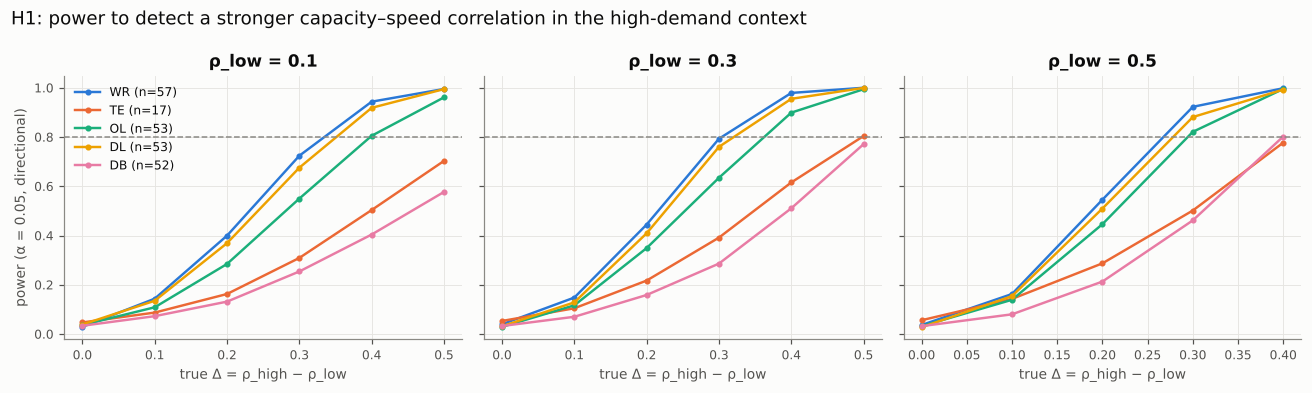

In [4]:
h1 = pl.read_parquet(OUT / 'power_h1.parquet')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, rl in zip(axes, [0.1, 0.3, 0.5]):
    for p in ['WR','TE','OL','DL','DB']:
        d = h1.filter((pl.col('pos')==p)&(pl.col('rho_low')==rl)).sort('delta')
        ax.plot(d['delta'], d[A], marker='o', ms=3, color=style.POSITION_COLOR[p], label=f"{p} (n={d['n_players'][0]})")
    ax.axhline(0.8, color=style.MUTED, ls='--', lw=1); ax.set_title(f'ρ_low = {rl}'); ax.set_xlabel('true Δ = ρ_high − ρ_low')
axes[0].set_ylabel('power (α = 0.05, directional)'); axes[0].legend(loc='upper left')
fig.suptitle('H1: power to detect a stronger capacity–speed correlation in the high-demand context', x=0.01, ha='left')
fig.tight_layout(); fig.savefig(FIG/'power_h1_curves.png', dpi=150); plt.show()

In [5]:
mrows=[]
for (p, rl), d in h1.group_by(['pos','rho_low']):
    d=d.sort('delta')
    mrows.append(dict(pos=p, rho_low=rl, n=d['n_players'][0], mde_alpha05=mde(d['delta'], d[A]), mde_holm=mde(d['delta'], d[A1]),
                      type1_alpha05=d.filter(pl.col('delta')==0)[A][0], sd_delta_hat_at_0=d.filter(pl.col('delta')==0)['sd_delta_hat'][0],
                      coverage95_at_0=d.filter(pl.col('delta')==0)['coverage95'][0]))
mde_h1 = pl.DataFrame(mrows).sort('pos','rho_low'); mde_h1

pos,rho_low,n,mde_alpha05,mde_holm,type1_alpha05,sd_delta_hat_at_0,coverage95_at_0
str,f64,i64,f64,f64,f64,f64,f64
"""DB""",0.1,52,NaN,NaN,0.0335,0.260966,0.9345
"""DB""",0.3,52,NaN,NaN,0.0325,0.246222,0.9345
"""DB""",0.5,52,0.399413,NaN,0.032,0.215856,0.9335
"""DL""",0.1,53,0.351235,0.38673,0.0385,0.130583,0.9285
"""DL""",0.3,53,0.320513,0.36458,0.0315,0.124154,0.933
…,…,…,…,…,…,…,…
"""TE""",0.3,17,0.497878,NaN,0.053,0.239023,0.9255
"""TE""",0.5,17,NaN,NaN,0.056,0.227612,0.9265
"""WR""",0.1,57,0.334624,0.373693,0.029,0.124003,0.934


**Reading.** NaN means 80% power is not reached anywhere in the grid (Δ ≤ 0.5, or ρ_high capped at 0.95). The MDE is the smallest true difference in correlations detectable with 80% power.

## 3. Plays do not substitute for players

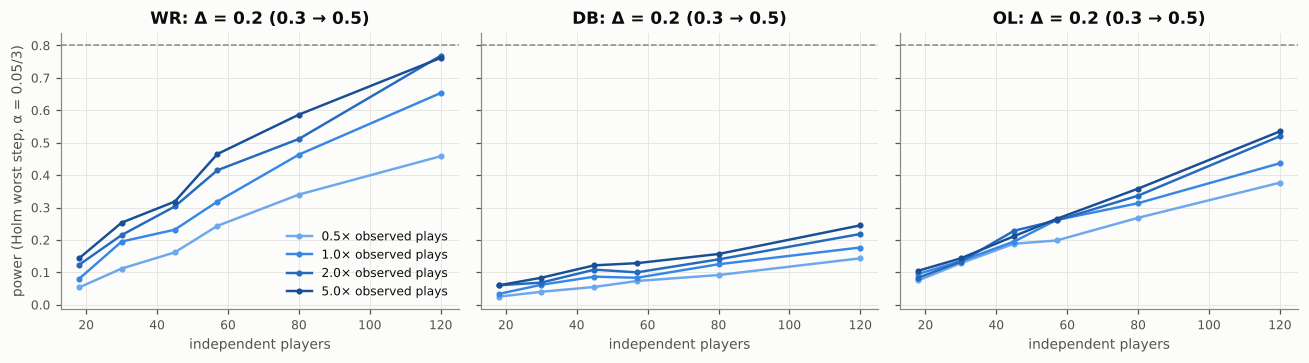

pos,n_players,0.5,1.0,2.0,5.0
str,i64,f64,f64,f64,f64
"""DB""",18,0.025,0.033333,0.06,0.06
"""DB""",30,0.04,0.061667,0.068333,0.083333
"""DB""",45,0.055,0.086667,0.108333,0.121667
"""DB""",57,0.073333,0.083333,0.1,0.128333
"""DB""",80,0.091667,0.125,0.14,0.156667
…,…,…,…,…,…
"""WR""",30,0.111667,0.195,0.215,0.253333
"""WR""",45,0.161667,0.231667,0.303333,0.318333
"""WR""",57,0.243333,0.318333,0.415,0.465


In [6]:
sen = pl.read_parquet(OUT / 'power_h1_sensitivity.parquet')
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, p in zip(axes, ['WR','DB','OL']):
    for k, ps in enumerate([0.5, 1.0, 2.0, 5.0]):
        d = sen.filter((pl.col('pos')==p)&(pl.col('play_scale')==ps)).sort('n_players')
        ax.plot(d['n_players'], d[A1], marker='o', ms=3, color=style.SEQ_BLUE[2+k], label=f'{ps}× observed plays')
    ax.axhline(0.8, color=style.MUTED, ls='--', lw=1); ax.set_title(f'{p}: Δ = 0.2 (0.3 → 0.5)'); ax.set_xlabel('independent players')
axes[0].set_ylabel('power (Holm worst step, α = 0.05/3)'); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG/'power_players_vs_plays.png', dpi=150); plt.show()
sen.pivot(index=['pos','n_players'], on='play_scale', values=A1).sort('pos','n_players')

Multiplying the number of plays per player by 5 barely changes power. The binding constraint is the number of independent players, because Δ is a between-player quantity.

In [7]:
val = pl.read_parquet(OUT / 'power_h1_playlevel_check.parquet'); val

pos,mode,mean_delta_hat,sd_delta_hat,mean_delta_raw,sd_delta_raw,coverage95,r_u,power_a0.0500,power_raw_a0.0500,power_a0.0167,power_raw_a0.0167
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""WR""","""normal""",0.207794,0.11064,0.202352,0.1021,0.945,0.697991,0.4675,0.5275,0.32,0.38
"""WR""","""empirical""",0.205554,0.114449,0.200782,0.105981,0.9275,0.697991,0.465,0.505,0.32,0.365
"""DB""","""normal""",0.192937,0.232179,0.177252,0.201792,0.9225,-0.576169,0.135,0.1675,0.0825,0.11
"""DB""","""empirical""",0.205788,0.224915,0.19111,0.193642,0.9275,-0.576169,0.1775,0.19,0.095,0.1125


Simulating every play with the **empirical, non-normal residuals** gives the same power as the player-level normal shortcut. The shortcut is therefore adequate.

## 4. H2: incremental value of tracked peak speed beyond the official 40 (WR deep routes)

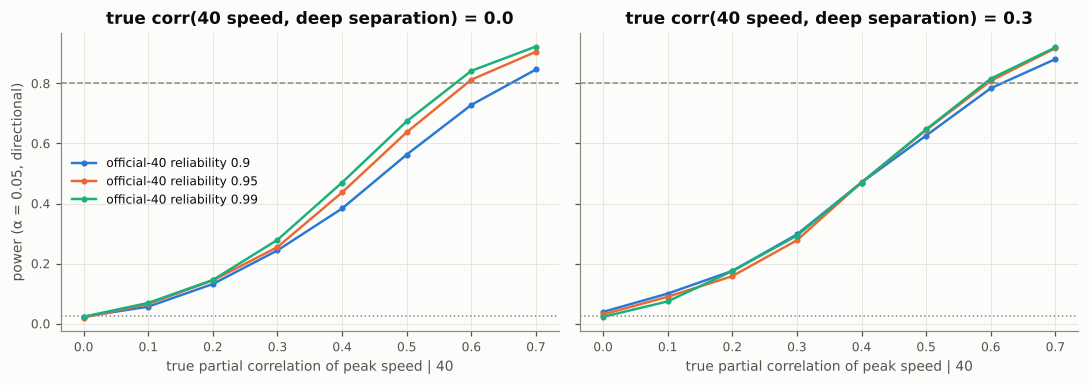

forty_rel,rho_forty,partial,power_a0.0500,power_a0.0167,mean_loo_dR2,p_loo_dR2_pos
f64,f64,f64,f64,f64,f64,f64
0.9,0.0,0.0,0.023,0.0085,-0.020585,0.1575
0.9,0.0,0.1,0.0565,0.0245,-0.017155,0.1915
0.9,0.0,0.2,0.132,0.0635,-0.006094,0.304
0.9,0.0,0.3,0.244,0.137,0.011388,0.46
0.9,0.0,0.4,0.3835,0.2275,0.035077,0.651
…,…,…,…,…,…,…
0.99,0.3,0.3,0.293,0.1505,0.019187,0.5495
0.99,0.3,0.4,0.47,0.3095,0.046898,0.7005
0.99,0.3,0.5,0.647,0.4805,0.08256,0.8415


In [8]:
h2 = pl.read_parquet(OUT / 'power_h2.parquet')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, rf in zip(axes, [0.0, 0.3]):
    for k, rel in enumerate([0.90, 0.95, 0.99]):
        d = h2.filter((pl.col('rho_forty')==rf)&(pl.col('forty_rel')==rel)).sort('partial')
        ax.plot(d['partial'], d[A], marker='o', ms=3, color=style.SERIES[k], label=f'official-40 reliability {rel}')
    ax.axhline(0.8, color=style.MUTED, ls='--', lw=1); ax.axhline(0.025, color=style.MUTED, ls=':', lw=1)
    ax.set_title(f'true corr(40 speed, deep separation) = {rf}'); ax.set_xlabel('true partial correlation of peak speed | 40')
axes[0].set_ylabel('power (α = 0.05, directional)'); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG/'power_h2_curves.png', dpi=150); plt.show()
h2.select('forty_rel','rho_forty','partial',A,A1,'mean_loo_dR2','p_loo_dR2_pos').sort('forty_rel','rho_forty','partial')

The primary family uses a fixed sequence (H1-WR, then H2), each at α = 0.05. Curves use that level; the Holm (m = 3) level is in the tables. The dotted line is the nominal directional size, 0.025.

The `partial = 0` rows give the **false "incremental value" rate**. This is the rejection rate when separation depends only on true 40 speed, but the official 40 is measured with error.

In [9]:
h2n = pl.read_parquet(OUT / 'power_h2_by_n.parquet')
h2n.pivot(index='n_players', on='partial', values=A).sort('n_players')

n_players,0.2,0.3,0.4
i64,f64,f64,f64
30,0.093,0.166,0.233
41,0.122,0.196,0.326
57,0.178,0.298,0.462
80,0.211,0.375,0.626
120,0.323,0.552,0.795
200,0.478,0.794,0.959


## 5. H5: OL comparison (difference-in-contrasts, normal approximation from simulated SDs)

In [10]:
from scipy import stats
sd = {r['pos']: r['sd_delta_hat_at_0'] for r in mde_h1.filter(pl.col('rho_low')==0.3).iter_rows(named=True)}
rows=[]
for dd in [0.1,0.2,0.3,0.4,0.5]:
    se = np.sqrt(sd['WR']**2 + sd['OL']**2)
    for a in (0.05, 0.05/3):
        rows.append(dict(diff_in_contrasts=dd, alpha=round(a,4), power=1-stats.norm.cdf(stats.norm.ppf(1-a/2) - dd/se)))
pl.DataFrame(rows).pivot(index='diff_in_contrasts', on='alpha', values='power')

diff_in_contrasts,0.05,0.0167
f64,f64,f64
0.1,0.076218,0.031091
0.2,0.183529,0.090773
0.3,0.354569,0.209825
0.4,0.561972,0.390489
0.5,0.753314,0.599069


## 6. Summary

The numbers are carried into `research_notes/power_analysis.md`. The confirmatory analysis must not change thresholds after seeing these curves; the protocol was frozen with them.